In [25]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns
from PIL import Image

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models

from torchvision import datasets
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

load_dotenv()
# 오류 발생시
sklearn.set_config(display="text")

[문제 1] 데이터 로드 & 증강 파이프라인 구성 (힌트 제공) (15점)

요구사항

- 입력 크기: 224 x 224

- 배치 크기: 32

- 훈련/검증 분리: 80 / 20

- 훈련(train)에만 증강 적용

- 클래스 수: 본인이 선택한 데이터셋 기준으로 명시 (예: 2진 분류 또는 다중 분류)

In [26]:
base_path = r"C:\kdt_0900_osh\ml\resource\datasets"

In [30]:
from kaggle.api.kaggle_api_extended import KaggleApi

api = KaggleApi()
api.authenticate()

os.makedirs(base_path, exist_ok=True)
# https://www.kaggle.com/datasets/mikoajfish99/lions-or-cheetahs-image-classification
api.dataset_download_files(r"mikoajfish99/lions-or-cheetahs-image-classification", path=base_path, unzip=True)

print("다운로드 완료")

Dataset URL: https://www.kaggle.com/datasets/mikoajfish99/lions-or-cheetahs-image-classification
다운로드 완료


In [41]:
file_path = os.path.join(base_path, r"lionchita")
file_path

'C:\\kdt_0900_osh\\ml\\resource\\datasets\\lionchita'

In [42]:
base_dataset = ImageFolder(file_path, transform=None)

In [43]:
base_dataset

Dataset ImageFolder
    Number of datapoints: 200
    Root location: C:\kdt_0900_osh\ml\resource\datasets\lionchita

In [44]:
train_subset, temp_subset = train_test_split(base_dataset, test_size=0.2, random_state=42)
val_subset, test_subset = train_test_split(temp_subset, test_size=0.5, random_state=42)

In [45]:
len(train_subset), len(val_subset), len(test_subset)

(160, 20, 20)

In [49]:
class DatasetWrapper(Dataset):
    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        x, y = self.dataset[idx]
        if self.transform:
            x = self.transform(x)
        return x, y

In [46]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

In [47]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

test_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

target_tarnsform = lambda y: torch.tensor([y], dtype=torch.float32)

In [50]:
train_dataset = DatasetWrapper(train_subset, transform=train_transform)
val_dataset = DatasetWrapper(val_subset, transform=test_transform)
test_dataset = DatasetWrapper(test_subset, transform=test_transform)

In [51]:
len(train_dataset), len(val_dataset), len(test_dataset)

(160, 20, 20)

In [53]:
class_dict = dict(enumerate(base_dataset.classes))
class_dict

{0: 'Cheetahs', 1: 'Lions'}

In [54]:
train_dataloader = DataLoader(train_dataset, shuffle=True, batch_size=32)
val_dataloader = DataLoader(val_dataset, shuffle=False, batch_size=32)
test_dataloader = DataLoader(test_dataset, shuffle=False, batch_size=32)

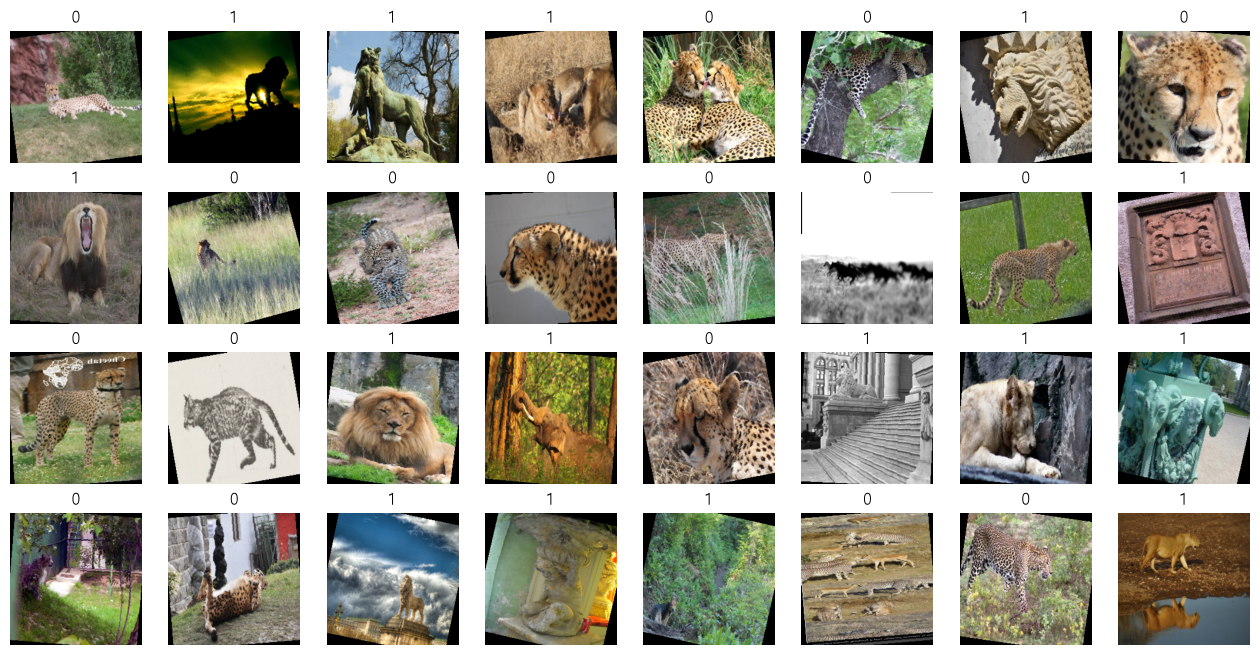

In [55]:
imgs, labels = next(iter(train_dataloader))

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(4, 8, figsize=(16, 8))

for ax, img, label in zip(axes.flatten(), imgs, labels):
    img = img * std + mean
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(label.item())
    ax.axis("off")

plt.show()

In [56]:
# 18. 캣도그 구별 모델 코드 보고 하기

현재 페이지 기준으로 lionchita는 치타와 사자 두 클래스로 된 이미지 200장이고, 훈련 데이터는 160장뿐이에요.
셋 중 하나를 고른다면 사전 학습된 ResNet을 먼저 시도하는 것을 권합니다. 이미지 특징을 잘 학습한 가중치로 시작할 수 있어 데이터가 적을 때 유리하고, 224×224 입력에도 잘 맞습니다. 마지막 분류층을 2개 출력으로 바꿔 미세 조정하면 돼요.
다만 ResNet이 반드시 가장 높은 정확도를 낸다고 단정할 수는 없습니다. 데이터가 적어 검증 세트 20장만으로는 모델 간 차이를 판단하기 어렵고, 클래스별 이미지 수와 촬영 조건도 영향을 줍니다. 같은 데이터 분할과 학습 설정으로 세 모델을 비교하고, 가능하면 여러 번 분할해 평균 검증 성능을 보는 게 가장 확실합니다.

Alexnet과 ResNet 둘 다 전이학습 모델인데 왜 ResNet이 더 나아?

둘 다 전이학습이지만, 사전 학습 가중치가 같다고 성능까지 같아지는 건 아니에요. ResNet을 먼저 권한 이유는 주로 구조와 학습 안정성 때문입니다.
- 잔차 연결(skip connection) 덕분에 깊은 신경망에서도 앞쪽 정보와 기울기가 잘 전달되어, 복잡한 이미지 특징을 학습하기 유리합니다.
- AlexNet은 비교적 오래된 구조라 층이 얕고, 현대적인 이미지 분류 기준에서는 ResNet 계열이 더 강한 특징 추출기로 쓰이는 경우가 많습니다.
- 이 데이터는 200장뿐이라 모델을 처음부터 학습하기보다 사전 학습 특징을 활용하는 게 중요하고, ResNet이 좋은 출발점일 가능성이 있습니다.